# **Previsão de Churn (Abandono) em Telecom (MLP - Sequential (tensorflow.keras))**

# 1. Importando bibliotecas

In [1]:
import sys

def in_colab():
    return 'google.colab' in sys.modules

In [2]:
if in_colab():
    !pip install optuna
    !pip install tensorflow
    !pip install matplotlib_venn

In [3]:
# Sistema e utilitários
import random
from copy import deepcopy
import warnings

# Bibliotecas principais
import pandas as pd
import numpy as np
import optuna

# Matplotlib
import matplotlib.pyplot as plt
from matplotlib.patches import Wedge, Circle, Rectangle
from matplotlib_venn import venn2

# Scikit-learn
from sklearn.metrics import accuracy_score, log_loss, classification_report, mean_squared_error
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import roc_auc_score, roc_curve
from sklearn.metrics import precision_score, recall_score, f1_score
from sklearn.metrics import precision_recall_curve
from sklearn.exceptions import ConvergenceWarning
from sklearn.compose import ColumnTransformer
from sklearn.discriminant_analysis import StandardScaler
from sklearn.utils import shuffle

# Tensorflow
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam, Nadam, RMSprop, SGD
from tensorflow.keras.regularizers import l2

c:\Users\caiof\Documents\Meus\_Estudos_\Faculdade\UFPE\2025.2\IF702 - REDES NEURAIS\Projetos\Projeto\env\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# Remove warnings:
warnings.filterwarnings("ignore", category=UserWarning)
warnings.filterwarnings("ignore", category=ConvergenceWarning)

# 2. Importando banco de dados


In [5]:
# Importar banco de dados
if in_colab():
    data = pd.read_csv("customer_churn_telecom_services.csv")
else:
    data = pd.read_csv("../customer_churn_telecom_services.csv")
data.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


# 3. Dividindo dados

In [6]:
def separa_classe(df_class):
    df_class = shuffle(df_class, random_state=42)

    n = len(df_class)
    train = df_class.iloc[:int(0.5*n)]
    val   = df_class.iloc[int(0.5*n):int(0.75*n)]
    test  = df_class.iloc[int(0.75*n):]

    return train, val, test


def balanceamento(df_maior, df_menor):
    df_menor_bal = df_menor.sample(n=len(df_maior), replace=True, random_state=42)
    return df_menor_bal


def junta_e_mistura(df_x, df_y):
  return shuffle(pd.concat([df_x, df_y]), random_state=42)

In [7]:
# Separar classes
# Classe 0 = Churn no
# Classe 1 = Churn yes
data_cl0 = data[data["Churn"] == "No"]
data_cl1 = data[data["Churn"] == "Yes"]

# Para cada classe, separar treino(50%), validação(25%) e teste(25%) de cada classe
data_cl0_train, data_cl0_val, data_cl0_test = separa_classe(data_cl0)
data_cl1_train, data_cl1_val, data_cl1_test = separa_classe(data_cl1)

# Balancear os dados de treino e validação da classe 2 até ter mesma quantidade que os da classe 1
data_cl1_train = balanceamento(data_cl0_train, data_cl1_train)
data_cl1_val = balanceamento(data_cl0_val, data_cl1_val)


# Embaralhar dados de treino, validação e teste
data_train = junta_e_mistura(data_cl0_train, data_cl1_train)
data_val = junta_e_mistura(data_cl0_val, data_cl1_val)
data_test = junta_e_mistura(data_cl0_test, data_cl1_test)

In [8]:
print("Tamanhos finais:")
print("Treino:", data_train.shape)
print("Validação:", data_val.shape)
print("Teste:", data_test.shape)

Tamanhos finais:
Treino: (5174, 20)
Validação: (2586, 20)
Teste: (1762, 20)


# 4. Tratamento de dados

In [9]:
# ===============================
# Funções de pré-processamento
# ===============================
def treat_missing(df):
    df = df.copy()

    # Strings vazias ou só espaços → NaN
    df = df.replace(r"^\s*$", np.nan, regex=True)

    print("Linhas removidas:", df.isna().any(axis=1).sum())

    # Remove linhas com qualquer NaN
    df = df.dropna().reset_index(drop=True)

    return df


def fix_inconsistencies(df):
    df = df.copy()

    # 1. TotalCharges (string -> numeric)
    df["TotalCharges"] = pd.to_numeric(df["TotalCharges"], errors="coerce")

    return df


def treating_data(df):
    df = df.copy()

    # ===============================
    # 1. Binárias Yes / No (TODAS)
    # ===============================
    yes_no_cols = [
        "Partner", "Dependents", "PhoneService",
        "PaperlessBilling", "MultipleLines",
        "OnlineSecurity", "OnlineBackup",
        "DeviceProtection", "TechSupport",
        "StreamingTV", "StreamingMovies"
    ]
    for col in yes_no_cols:
        if col in df.columns:
            df[col] = (df[col] == "Yes").astype(int)

    # ===============================
    # 2. Gender
    # ===============================
    df["gender"] = (df["gender"] == "Male").astype(int)

    # ===============================
    # 3. One-Hot Encoding
    # ===============================
    cat_cols = [
        "InternetService",
        "Contract",
        "PaymentMethod"
    ]
    df = pd.get_dummies(
        df,
        columns=cat_cols,
        drop_first=False,
        dtype=int
    )

    # ===============================
    # 4. Agregação de serviços (remove ruído)
    # ===============================
    service_cols = [
        "OnlineSecurity", "OnlineBackup",
        "DeviceProtection", "TechSupport",
        "StreamingTV", "StreamingMovies"
    ]

    df["num_services"] = df[service_cols].sum(axis=1)
    df.drop(columns=service_cols, inplace=True)

    return df


def new_features(df):
    df["AvgMonthlyCharge"] = df["TotalCharges"] / (df["tenure"] + 1)
    df["is_new_customer"] = (df["tenure"] <= 6).astype(int)
    return df


def is_binary(col):
    return set(col.dropna().unique()) <= {0, 1}

In [10]:
# 0. Copia banco de dados
tratando_train = data_train.copy()
tratando_val = data_val.copy()
tratando_test = data_test.copy()

In [11]:
#1. Trata dados faltando:
tratando_train = treat_missing(tratando_train)
tratando_val = treat_missing(tratando_val)
tratando_test = treat_missing(tratando_test)

Linhas removidas: 6
Linhas removidas: 2
Linhas removidas: 3


In [12]:
# 2. Muda target de "Yes"/"No" para 1/0:
tratando_train["Churn"] = (tratando_train["Churn"] == "Yes").astype(int)
tratando_val["Churn"] = (tratando_val["Churn"] == "Yes").astype(int)
tratando_test["Churn"] = (tratando_test["Churn"] == "Yes").astype(int)

In [13]:
# 3. Fix Inconsistências
tratando_train = fix_inconsistencies(tratando_train)
tratando_val = fix_inconsistencies(tratando_val)
tratando_test = fix_inconsistencies(tratando_test)

In [14]:
# 4. Tratando dados:
tratando_train = treating_data(tratando_train)
tratando_val = treating_data(tratando_val)
tratando_test = treating_data(tratando_test)

In [15]:
# 5. Add novas features:
tratando_train = new_features(tratando_train)
tratando_val = new_features(tratando_val)
tratando_test = new_features(tratando_test)

In [16]:
# 6. Separa valores target do resto do datasets:
target = "Churn"

# - Separa valores target de treino, validação e teste:
y_train = tratando_train[target]
y_val   = tratando_val[target]
y_test  = tratando_test[target]

# - Remover os valores target dos datasets para passar ao preprocessor:
tratando_train = tratando_train.drop(columns=[target])
tratando_val = tratando_val.drop(columns=[target])
tratando_test = tratando_test.drop(columns=[target])

In [17]:
# 7. Normalização
# Separa colunas entree categoricas e numericas:
binary_cols = [
    c for c in tratando_train.columns
    if c != target and is_binary(tratando_train[c])
]

numeric_cols = [
    c for c in tratando_train.columns
    if c != target and c not in binary_cols
]

# Cria preprocessor:
preprocessor = ColumnTransformer(
    transformers=[
        ("num", StandardScaler(), numeric_cols),
        ("bin", "passthrough", binary_cols)
    ]
)

# Fit no treino:
preprocessor.fit(tratando_train)

# Transform no resto:
x_train = preprocessor.transform(tratando_train)
x_val   = preprocessor.transform(tratando_val)
x_test  = preprocessor.transform(tratando_test)

In [18]:
print("Formato dos dados:")
print("Dados completos:", x_train)
print("Shape:", x_train.shape)
print("Uma linha:", x_train[0])
print("Tipo:", type(x_train))

Formato dos dados:
Dados completos: [[-0.61144452  1.25319085 -0.33978022 ...  0.          0.
   0.        ]
 [ 1.33673383 -0.64754343  0.39551809 ...  1.          0.
   0.        ]
 [ 0.9636784  -0.28039605  0.49126101 ...  0.          0.
   0.        ]
 ...
 [-0.69434573 -1.69979836 -0.83126357 ...  0.          0.
   0.        ]
 [-0.73579633  0.94401411 -0.52253314 ...  1.          0.
   0.        ]
 [-0.07258668 -1.71033848 -0.72366395 ...  0.          0.
   0.        ]]
Shape: (5168, 23)
Uma linha: [-0.61144452  1.25319085 -0.33978022  1.14340129  1.0931436   0.
  0.          0.          1.          1.          1.          1.
  0.          1.          0.          0.          1.          0.
  0.          1.          0.          0.          0.        ]
Tipo: <class 'numpy.ndarray'>


# 5. Hiperparametros

In [19]:
hidden_layers_limits = (2, 3)
layer_sizes_limits = (16, 256)
learning_rate_limits = (1e-6, 1e-3)
activation_functions = ["relu", "tanh", "elu", "LeakyReLU"]
optimizators = ["adam", "nadam", "rmsprop", "sgd"]
L2_regularization_limits = (1e-6, 1e-3)
batch_size_limits = (64, 256)
dropout_limits = [0.00, 0.05, 0.10, 0.15, 0.20]
epochs = 10000
patience = 20
random_state = random.randint(0, 99999)
trials_optuna = 40
threshold = 0.5

# 6. Treinamento

In [20]:
def fix_random_seed(seed=42):
    np.random.seed(seed)
    random.seed(seed)
    tf.random.set_seed(seed)

fix_random_seed(random_state)
print("random state:", random_state)

random state: 66895


In [21]:
# Calcula KS:
def calcula_ks(y_true, y_proba, plot=False):
    # y_proba deve ser prob da classe positiva (1)
    probs = y_proba
    labels = y_true

    # Dividir probabilidades por classe
    probs_0 = np.sort(probs[labels == 0])
    probs_1 = np.sort(probs[labels == 1])

    # CDFs (acumuladas)
    cdf_0 = np.arange(1, len(probs_0) + 1) / len(probs_0)
    cdf_1 = np.arange(1, len(probs_1) + 1) / len(probs_1)

    # Emparelhamento por grade comum de thresholds
    all_probs = np.sort(np.unique(probs))
    cdf0_interp = np.interp(all_probs, probs_0, cdf_0)
    cdf1_interp = np.interp(all_probs, probs_1, cdf_1)

    # KS por diferença máxima
    ks_values = np.abs(cdf1_interp - cdf0_interp)
    ks_stat = np.max(ks_values)
    best_threshold = all_probs[np.argmax(ks_values)]

    if plot:
        # Resultados:
        print("KS Statistic:", ks_stat)
        print("Best threshold:", best_threshold)
        # Grafico:
        plt.figure(figsize=(7, 5))
        plt.plot(all_probs, cdf0_interp, label="Class 0", linewidth=2)
        plt.plot(all_probs, cdf1_interp, label="Class 1", linewidth=2)

        # Linha pontilhada do KS
        plt.plot([best_threshold, best_threshold],
                [cdf0_interp[np.argmax(ks_values)], cdf1_interp[np.argmax(ks_values)]],
                'k--', linewidth=2, label=f'KS = {ks_stat:.3f} em {best_threshold:.3f}')

        plt.title("KS Statistic Plot")
        plt.xlabel("Threshold")
        plt.ylabel("Percentage below threshold")

        plt.legend()
        plt.grid(True)
        plt.show()
    return ks_stat, best_threshold

In [22]:
def monta_modelo(**params):
    # Seleção dinâmica do otimizador
    optimizers_dict = {
        "adam": Adam(learning_rate=params["learning_rate"]),
        "nadam": Nadam(learning_rate=params["learning_rate"]),
        "rmsprop": RMSprop(learning_rate=params["learning_rate"]),
        "sgd": SGD(learning_rate=params["learning_rate"])
    }
    optimizer = optimizers_dict[params["optimizator"]]

    activation_functions = {
        "relu": "relu",
        "tanh": "tanh",
        "elu": "elu",
        "LeakyReLU": tf.keras.layers.LeakyReLU()}
    activation = activation_functions[params["activation_func"]]

    modelo = Sequential()

    # Primeira camada
    modelo.add(Dense(
        params["hidden_layer_sizes"][0],
        activation=activation,
        kernel_regularizer=l2(params["L2_regularization"]),
        input_shape=params["input_size"]
    ))
    modelo.add(Dropout(params["dropouts"][0]))

    # Demais camadas ocultas
    for units, dp in zip(params["hidden_layer_sizes"][1:], params["dropouts"][1:]):
        modelo.add(Dense(
            units,
            activation=activation,
            kernel_regularizer=l2(params["L2_regularization"])
        ))
        modelo.add(Dropout(dp))

    # Camada final
    modelo.add(Dense(1, activation='sigmoid'))

    modelo.compile(
        optimizer=optimizer,
        loss="binary_crossentropy",
        metrics=["binary_crossentropy"]
    )

    return modelo

In [23]:
# Processo de treino do optuna
def objective(trial):
  # Hiperparâmetros escolhidos automaticamente:
  hidden_layers_number = trial.suggest_int("hidden_layers", hidden_layers_limits[0], hidden_layers_limits[-1])
  layers = []
  dropouts = []
  for i in range(hidden_layers_number):
    units_in_layer =  trial.suggest_int(f"units_in_layer_{i}", layer_sizes_limits[0], layer_sizes_limits[-1])
    layers.append(units_in_layer)
    dropout_in_layer =  trial.suggest_categorical(f"dropout_in_layer_{i}", dropout_limits)
    dropouts.append(dropout_in_layer)

  params = {
      "input_size": (x_train.shape[1],),
      "hidden_layer_sizes": layers,
      "dropouts": dropouts,
      "learning_rate": trial.suggest_float("learning_rate", learning_rate_limits[0], learning_rate_limits[-1], log=True),
      "activation_func": trial.suggest_categorical("activation", activation_functions),
      "optimizator": trial.suggest_categorical("optimizator", optimizators),
      "L2_regularization": trial.suggest_float("L2_regularization", L2_regularization_limits[0], L2_regularization_limits[-1], log=True)
      }

  # Modelo:
  model = monta_modelo(**params)

  # Early stopping + salvar melhor modelo:
  early = EarlyStopping(
    monitor="val_loss",
    patience=patience,
    min_delta=1e-6,
    restore_best_weights=True,
    mode="min",
    verbose=0
    )

  # Treino:
  history = model.fit(
    x_train, y_train,
    validation_data=(x_test, y_test),
    epochs=epochs,
    batch_size= trial.suggest_int("batch_size", batch_size_limits[0], batch_size_limits[-1]),
    callbacks=[early],
    verbose=0
  )

  # Calcula ks:
  pred_prob = model.predict(x_val).ravel()
  best_ks, _ = calcula_ks(y_val, pred_prob)

  return best_ks

In [ ]:
# Optuna executando busca por melhores hiperparametros
#study = optuna.create_study(direction="maximize")
#study.optimize(objective, n_trials=trials_optuna)

[I 2025-12-16 12:53:36,500] A new study created in memory with name: no-name-1dca0f5c-b52d-4cfa-aae1-a28c310f5fc4


81/81 ━━━━━━━━━━━━━━━━━━━━ 5s 30ms/step


[I 2025-12-16 12:55:27,359] Trial 0 finished with value: 0.5311548159153678 and parameters: {'hidden_layers': 3, 'units_in_layer_0': 89, 'dropout_in_layer_0': 0.05, 'units_in_layer_1': 55, 'dropout_in_layer_1': 0.2, 'units_in_layer_2': 159, 'dropout_in_layer_2': 0.05, 'learning_rate': 6.498419481702447e-06, 'activation': 'relu', 'optimizator': 'rmsprop', 'L2_regularization': 8.304071388075617e-06, 'batch_size': 170}. Best is trial 0 with value: 0.5311548159153678.


81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


[I 2025-12-16 12:57:08,022] Trial 1 finished with value: 0.5635939898460297 and parameters: {'hidden_layers': 2, 'units_in_layer_0': 77, 'dropout_in_layer_0': 0.05, 'units_in_layer_1': 181, 'dropout_in_layer_1': 0.15, 'learning_rate': 2.1532650853433163e-05, 'activation': 'LeakyReLU', 'optimizator': 'adam', 'L2_regularization': 0.0002866449752438247, 'batch_size': 106}. Best is trial 1 with value: 0.5635939898460297.


81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step


... (71 outputs left out)

81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


[I 2025-12-16 15:07:29,072] Trial 38 finished with value: 0.5372399044233318 and parameters: {'hidden_layers': 2, 'units_in_layer_0': 81, 'dropout_in_layer_0': 0.15, 'units_in_layer_1': 149, 'dropout_in_layer_1': 0.2, 'learning_rate': 0.00010905482441954401, 'activation': 'LeakyReLU', 'optimizator': 'rmsprop', 'L2_regularization': 0.0002461921465671558, 'batch_size': 210}. Best is trial 1 with value: 0.5635939898460297.


81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step


[I 2025-12-16 15:07:43,641] Trial 39 finished with value: 0.5333768310460345 and parameters: {'hidden_layers': 2, 'units_in_layer_0': 202, 'dropout_in_layer_0': 0.05, 'units_in_layer_1': 212, 'dropout_in_layer_1': 0.05, 'learning_rate': 0.00017654681421160124, 'activation': 'LeakyReLU', 'optimizator': 'nadam', 'L2_regularization': 4.405311735624782e-06, 'batch_size': 64}. Best is trial 1 with value: 0.5635939898460297.


In [ ]:
# Resultado do treino com optuna
#print("Melhores parâmetros:", study.best_params)
#print("Melhor ks:", study.best_value)

Melhores parâmetros: {'hidden_layers': 2, 'units_in_layer_0': 77, 'dropout_in_layer_0': 0.05, 'units_in_layer_1': 181, 'dropout_in_layer_1': 0.15, 'learning_rate': 2.1532650853433163e-05, 'activation': 'LeakyReLU', 'optimizator': 'adam', 'L2_regularization': 0.0002866449752438247, 'batch_size': 106}
Melhor ks: 0.5635939898460297


In [24]:
# Treinamento do Modelo final usando os melhores hiperparametros

# Melhores hiperparametros:
#best_params = study.best_params
best_params = {'hidden_layers': 2, 'units_in_layer_0': 77, 'dropout_in_layer_0': 0.05, 'units_in_layer_1': 181, 'dropout_in_layer_1': 0.15, 'learning_rate': 2.1532650853433163e-05, 'activation': 'LeakyReLU', 'optimizator': 'adam', 'L2_regularization': 0.0002866449752438247, 'batch_size': 106}


# Reconstruir arquitetura:
n_layers = best_params["hidden_layers"]
layer_sizes = []
dropouts_values = []
for i in range(n_layers):
  layer_sizes.append(best_params[f"units_in_layer_{i}"])
  dropouts_values.append(best_params[f"dropout_in_layer_{i}"])

params = {
    "input_size": (x_train.shape[1],),
    "hidden_layer_sizes": layer_sizes,
    "dropouts": dropouts_values,
    "learning_rate": best_params["learning_rate"],
    "activation_func": best_params["activation"],
    "optimizator": best_params["optimizator"],
    "L2_regularization": best_params["L2_regularization"],
    }

# Cria modelo final:
final_model = monta_modelo(**params)

In [25]:
#Treinamento do modelo final

# Early stopping + salvar melhor modelo:
early = EarlyStopping(
  monitor="val_loss",
  patience=patience,
  min_delta=1e-6,
  restore_best_weights=True,
  mode="min",
  verbose=2
  )

# Treino:
history = final_model.fit(
  x_train, y_train,
  validation_data=(x_test, y_test),
  epochs=epochs,
  batch_size= best_params["batch_size"],
  callbacks=[early],
  verbose=1
)

Epoch 1/10000
49/49 ━━━━━━━━━━━━━━━━━━━━ 5s 13ms/step - binary_crossentropy: 0.6867 - loss: 0.7278 - val_binary_crossentropy: 0.7093 - val_loss: 0.7504
Epoch 2/10000
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - binary_crossentropy: 0.6614 - loss: 0.7025 - val_binary_crossentropy: 0.6730 - val_loss: 0.7141
Epoch 3/10000
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_crossentropy: 0.6374 - loss: 0.6785 - val_binary_crossentropy: 0.6449 - val_loss: 0.6859
Epoch 4/10000
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_crossentropy: 0.6174 - loss: 0.6584 - val_binary_crossentropy: 0.6225 - val_loss: 0.6635
Epoch 5/10000
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_crossentropy: 0.6006 - loss: 0.6416 - val_binary_crossentropy: 0.6037 - val_loss: 0.6447
Epoch 6/10000
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_crossentropy: 0.5841 - loss: 0.6250 - val_binary_crossentropy: 0.5887 - val_loss: 0.6296
Epoch 7/10000
49/49 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - binary_crossentropy: 0.5705 - loss: 0.

# 7. Analize de desempenho

In [26]:
# === 1. Obter previsões (treino, validação e teste) ===
y_train_pred = (final_model.predict(x_train) >= threshold).astype(int)
y_val_pred = (final_model.predict(x_val) >= threshold).astype(int)
y_test_pred = (final_model.predict(x_test) >= threshold).astype(int)


y_train_proba = final_model.predict(x_train).ravel()
y_val_proba = final_model.predict(x_val).ravel()
y_test_proba = final_model.predict(x_test).ravel()

162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 959us/step
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 853us/step
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 942us/step
162/162 ━━━━━━━━━━━━━━━━━━━━ 0s 711us/step
81/81 ━━━━━━━━━━━━━━━━━━━━ 0s 845us/step
55/55 ━━━━━━━━━━━━━━━━━━━━ 0s 876us/step


In [27]:
# === 2. Relatórios de classificação (treino, validação, teste) ===
print("==== CLASSIFICATION REPORT - TREINO ====")
print(classification_report(y_train, y_train_pred))
print(f"Accuracy no treino: {accuracy_score(y_train, y_train_pred):.4f}")
print()

print("==== CLASSIFICATION REPORT - VALIDAÇÃO ====")
print(classification_report(y_val, y_val_pred))
print(f"Accuracy na validação: {accuracy_score(y_val, y_val_pred):.4f}")
print()

print("==== CLASSIFICATION REPORT - TESTE ====")
print(classification_report(y_test, y_test_pred))
print(f"Accuracy no teste: {accuracy_score(y_test, y_test_pred):.4f}")

==== CLASSIFICATION REPORT - TREINO ====
              precision    recall  f1-score   support

           0       0.81      0.75      0.78      2581
           1       0.77      0.83      0.80      2587

    accuracy                           0.79      5168
   macro avg       0.79      0.79      0.79      5168
weighted avg       0.79      0.79      0.79      5168

Accuracy no treino: 0.7901

==== CLASSIFICATION REPORT - VALIDAÇÃO ====
              precision    recall  f1-score   support

           0       0.78      0.72      0.75      1291
           1       0.74      0.80      0.77      1293

    accuracy                           0.76      2584
   macro avg       0.76      0.76      0.76      2584
weighted avg       0.76      0.76      0.76      2584

Accuracy na validação: 0.7589

==== CLASSIFICATION REPORT - TESTE ====
              precision    recall  f1-score   support

           0       0.90      0.73      0.81      1291
           1       0.51      0.78      0.62       468

In [28]:
# === 3. Precision, Recall e F1 ===
print("Precision:", precision_score(y_test, y_test_pred))
print("Recall:", recall_score(y_test, y_test_pred))
print("F1-Score:", f1_score(y_test, y_test_pred))

Precision: 0.5104311543810849
Recall: 0.7841880341880342
F1-Score: 0.6183656276326874


In [29]:
# === 4. MSE (Erro Médio Quadrado) ===
print("MSE Treino:", mean_squared_error(y_train, y_train_pred))
print("MSE Validação:", mean_squared_error(y_val, y_val_pred))
print("MSE Teste:", mean_squared_error(y_test, y_test_pred))

MSE Treino: 0.20994582043343654
MSE Validação: 0.24109907120743035
MSE Teste: 0.25753268902785675


In [30]:
# === 5. Entropia Cruzada (Log Loss) ===
print("Log Loss Treino:", log_loss(y_train, y_train_proba))
print("Log Loss Validação:", log_loss(y_val, y_val_proba))
print("Log Loss Teste:", log_loss(y_test, y_test_proba))

Log Loss Treino: 0.4437986763499816
Log Loss Validação: 0.5054492676626186
Log Loss Teste: 0.4870364275065371


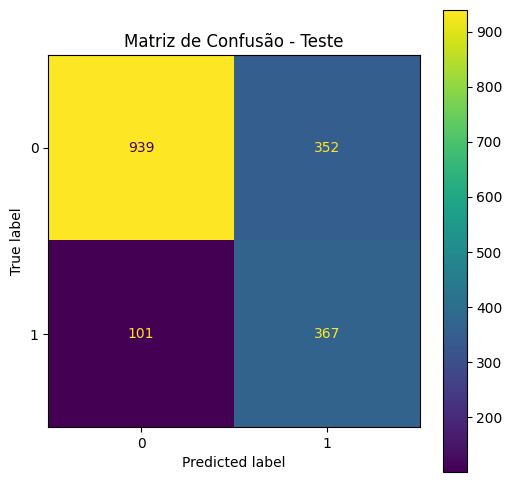

In [31]:
# === 6. Matriz de Confusão ===
fig, ax = plt.subplots(figsize=(6,6))
ConfusionMatrixDisplay.from_predictions(y_test, y_test_pred, ax=ax)
plt.title("Matriz de Confusão - Teste")
plt.show()

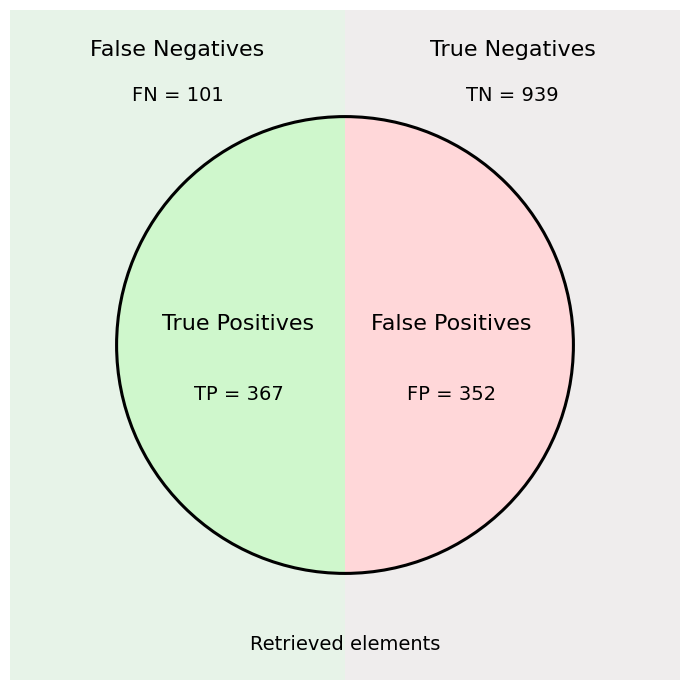

In [32]:
# === 7. Diagrama TN, FP, FN, TP ===
tn, fp, fn, tp = confusion_matrix(y_test, y_test_pred).ravel()

fig, ax = plt.subplots(figsize=(7,7))
ax.set_aspect('equal')
ax.set_xlim(-1.1, 1.1)
ax.set_ylim(-1.1, 1.1)
ax.axis('off')

# ==========================================
# 1) FUNDOS (fora do círculo)
# ==========================================

# Esquerda (False Negatives)
bg_left  = Rectangle((-1.1, -1.1), 1.1, 2.2, facecolor='#e7f3e8', edgecolor='none', zorder=0)

# Direita (True Negatives)
bg_right = Rectangle((0.0, -1.1), 1.1, 2.2, facecolor='#efeded', edgecolor='none', zorder=0)

ax.add_patch(bg_left)
ax.add_patch(bg_right)

# ==========================================
# 2) METADE INTERNA DO CÍRCULO (TP e FP)
# ==========================================

radius = 0.75
center = (0, 0)

# TP = metade esquerda interna
tp_wedge = Wedge(center, radius, 90, 270, facecolor='#cff7cc', edgecolor='none', zorder=1)
# FP = metade direita interna
fp_wedge = Wedge(center, radius, 270, 90, facecolor='#ffd7d9', edgecolor='none', zorder=1)

ax.add_patch(tp_wedge)
ax.add_patch(fp_wedge)

# Contorno do círculo
ax.add_patch(Circle(center, radius, facecolor='none', edgecolor='black', lw=2.2, zorder=3))

# ==========================================
# 3) TEXTOS
# ==========================================

# ---- Regiões externas ----
# False Negatives (topo esquerdo)
ax.text(-0.55, 0.95, "False Negatives", fontsize=16, ha='center')
ax.text(-0.55, 0.80, f"FN = {fn}", fontsize=14, ha='center')

# True Negatives (topo direito)
ax.text(0.55, 0.95, "True Negatives", fontsize=16, ha='center')
ax.text(0.55, 0.80, f"TN = {tn}", fontsize=14, ha='center')

# ---- Regiões internas ----
ax.text(-0.35, 0.05, "True Positives", fontsize=16, ha='center')
ax.text(-0.35, -0.18, f"TP = {tp}", fontsize=14, ha='center')

ax.text( 0.35, 0.05, "False Positives", fontsize=16, ha='center')
ax.text( 0.35, -0.18, f"FP = {fp}", fontsize=14, ha='center')

# Texto inferior
ax.text(0, -1.0, "Retrieved elements", fontsize=14, ha='center')

plt.tight_layout()
plt.show()

KS Statistic: 0.5210973457270927
Best threshold: 0.44053385


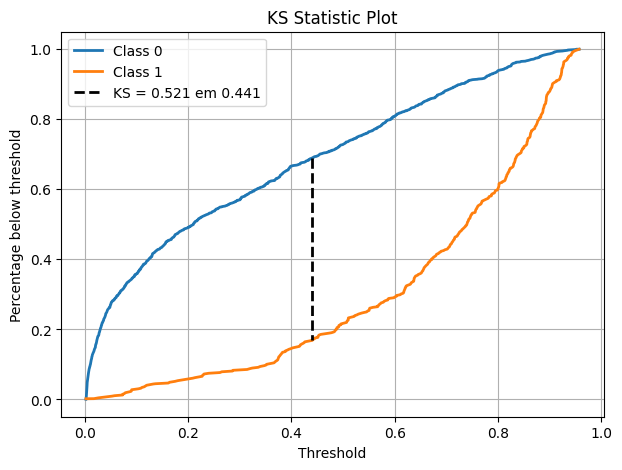

(np.float64(0.5210973457270927), np.float32(0.44053385))

In [33]:
# === 8. Teste Kolmogorov-Smirnov (KS) ===
calcula_ks(y_test, y_test_proba, True)

In [34]:
# === 9. AUROC ===
auc = roc_auc_score(y_test, y_test_proba)
print("AUC (Área sob a ROC):", auc)

AUC (Área sob a ROC): 0.8412969142055122


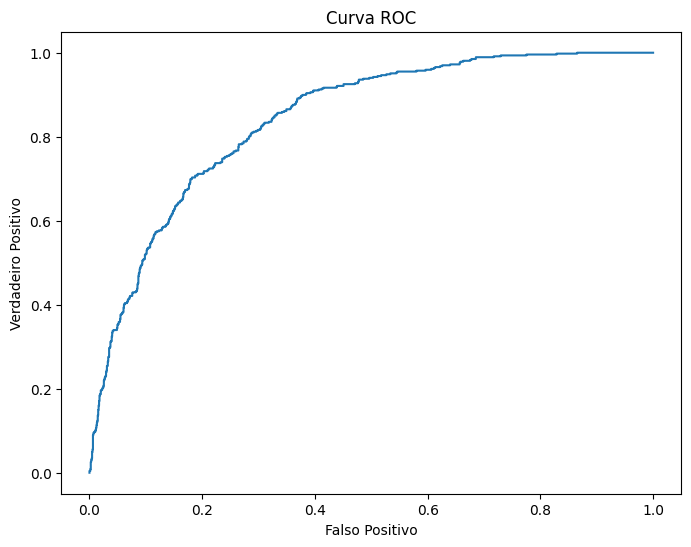

In [35]:
# === 9.5. Curva ROC ===
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)
plt.figure(figsize=(8,6))
plt.plot(fpr, tpr)
plt.title("Curva ROC")
plt.xlabel("Falso Positivo")
plt.ylabel("Verdadeiro Positivo")
plt.show()

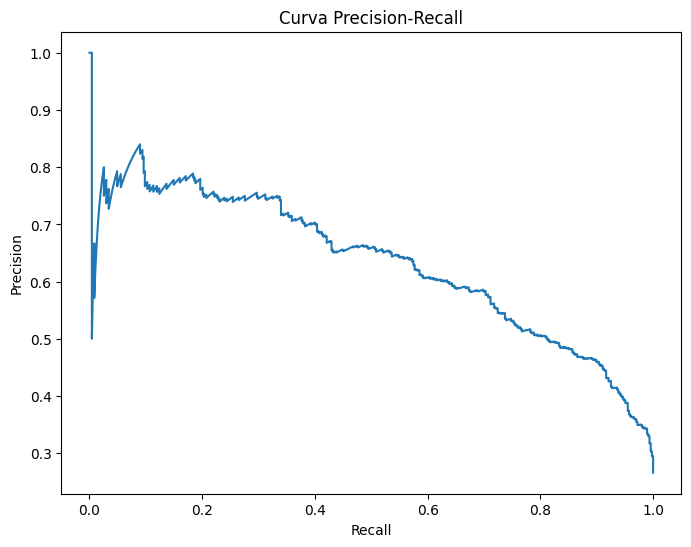

In [36]:
# === 10. Curva Precision-Recall ===
prec, rec, thr = precision_recall_curve(y_test, y_test_proba)
plt.figure(figsize=(8,6))
plt.plot(rec, prec)
plt.title("Curva Precision-Recall")
plt.xlabel("Recall")
plt.ylabel("Precision")
plt.show()

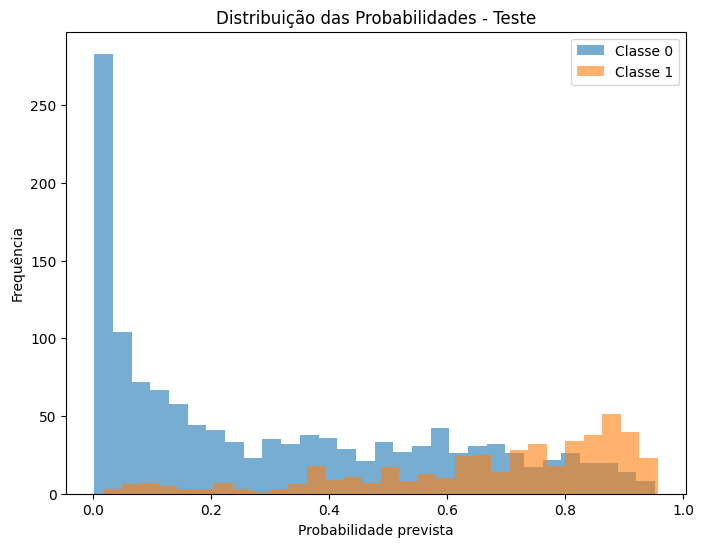

In [37]:
# === 11. Distribuição das probabilidades ===
plt.figure(figsize=(8,6))
plt.hist(y_test_proba[y_test==0], bins=30, alpha=0.6, label='Classe 0')
plt.hist(y_test_proba[y_test==1], bins=30, alpha=0.6, label='Classe 1')
plt.title("Distribuição das Probabilidades - Teste")
plt.xlabel("Probabilidade prevista")
plt.ylabel("Frequência")
plt.legend()
plt.show()